# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def get_cords(table):
    return table.iloc[:, 0].values, table.iloc[:, 1].values

def plot_table(table, colors = 'blue', is_clustered = False):
    x = table.iloc[:, 0]
    y = table.iloc[:, 1]
    
    plt.figure(figsize = (8, 8))
    plt.scatter(x, y, c = colors, marker = 'o', s = 10)
    
    if is_clustered:
        plt.title("Точки с кластеризацией")
    else:
        plt.title("Точки без кластеризации")
        
    plt.xlabel("Ось X")
    plt.ylabel("Ось Y")
    plt.grid(True)
    plt.axis('equal')
    plt.show()

def find(table, colors, metric = 'euclidian'):
    x, y = get_cords(table)
    unique_colors = np.unique(colors)
    centers = []
    
    for color in unique_colors:
        if color == 'black':
            continue
        ind = np.where(colors == color)[0]
        cluster_x = x[ind]
        cluster_y = y[ind]
        mn = float('inf')
        best = None

        for i in range(len(ind)):
            if metric == 'manhattan':
                distances = np.abs(cluster_x - cluster_x[i]) + np.abs(cluster_y - cluster_y[i])
            else:
                distances = np.sqrt((cluster_x - cluster_x[i])**2 + (cluster_y - cluster_y[i])**2)
            cur = np.sum(distances)
            if cur < mn:
                mn = cur
                best = (float(cluster_x[i]), float(cluster_y[i]))

        print(f"Лучшая точка '{color}': {best}")
        centers.append(best)
    sum_x, sum_y = 0, 0
    for p in centers:
        sum_x += p[0]
        sum_y += p[1]
    avg_x = (sum_x / len(centers)) * 1000
    avg_y = (sum_y / len(centers)) * 1000
    print(f"Усреднение: {avg_x}, {avg_y}")

t0 = pd.read_excel('0.xls')
t1 = pd.read_excel('1.xls')
t2 = pd.read_excel('2.xlsx')
t3 = pd.read_excel('3.xlsx')
t4 = pd.read_excel('4.xlsx')
t5 = pd.read_excel('5.xlsx')

colors_list = ['red', 'green', 'magenta']

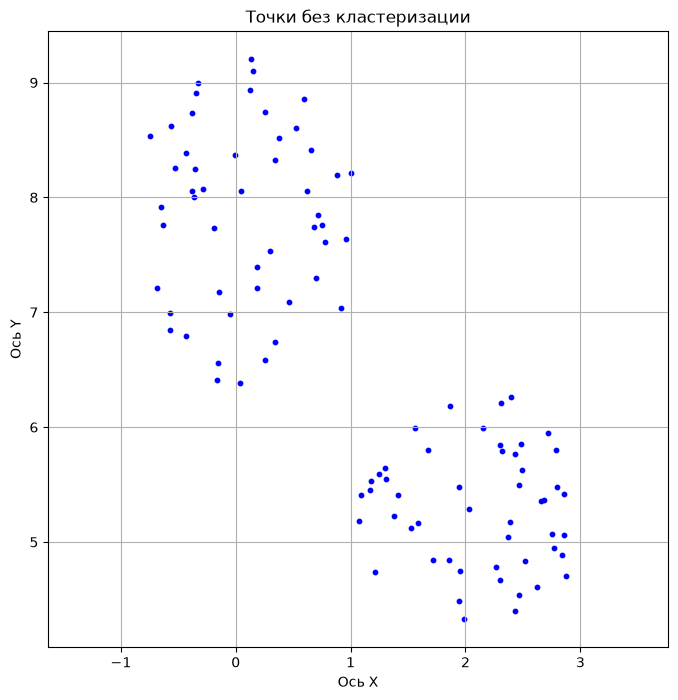

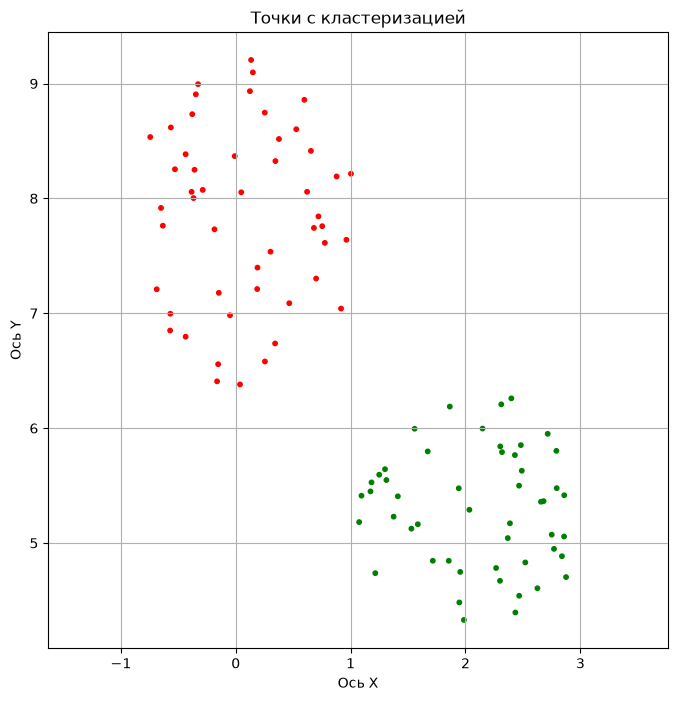

Лучшая точка 'green': (2.03390100209471, 5.28929590079911)
Лучшая точка 'red': (0.0481115536116194, 8.0530509124927)
Усреднение: 1041.0062778531646, 6671.173406645906


In [104]:
plot_table(t0)
x0, y0 = get_cords(t0)
color0 = np.where(y0 > x0 + 5, 'red', 'green')
plot_table(t0, color0, True)
find(t0, color0)

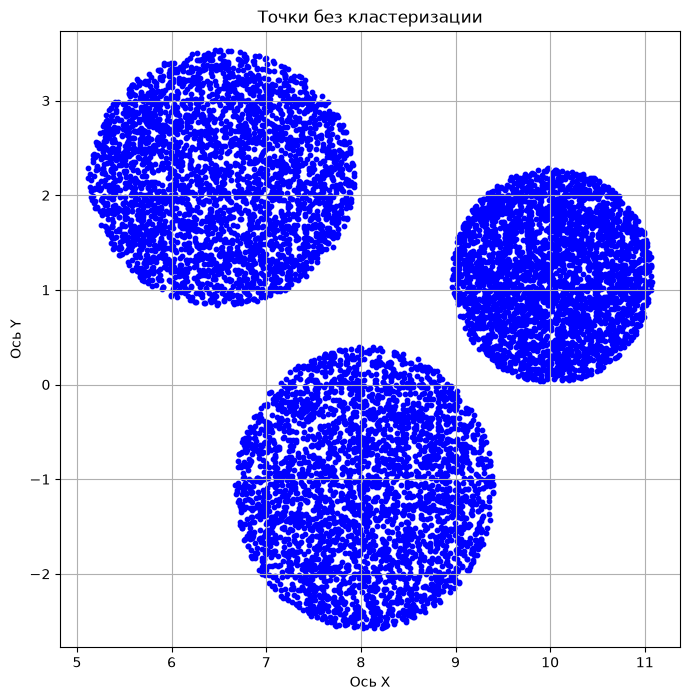

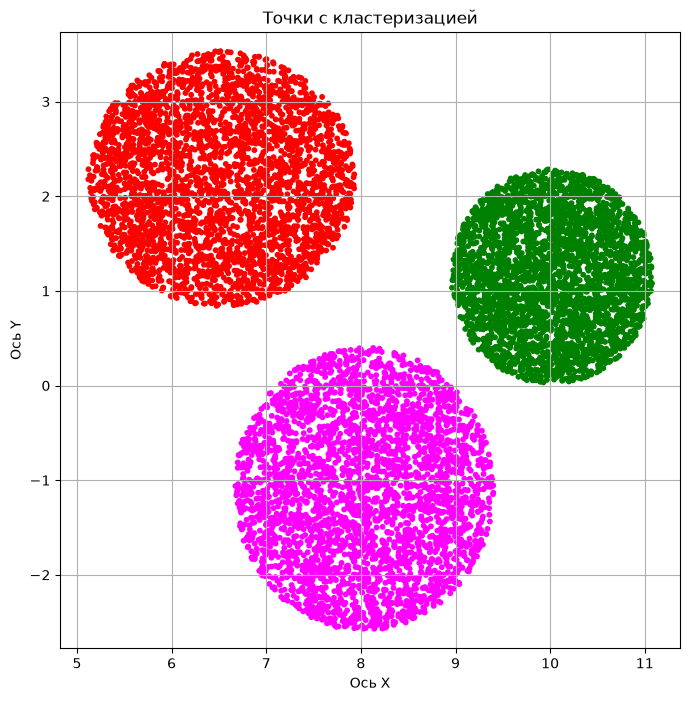

Лучшая точка 'green': (10.0225353109378, 1.15420059917185)
Лучшая точка 'magenta': (8.04007453084081, -1.10870556888781)
Лучшая точка 'red': (6.46998257368897, 2.16976099669024)
Усреднение: 8177.5308051558595, 738.4186756580933


In [105]:
plot_table(t1)
x1, y1 = get_cords(t1)
cond1 = [(x1 - 6.5) ** 2 + (y1 - 2.2) ** 2 < 1.5 ** 2,
         (x1 - 10) ** 2 + (y1 - 1.2) ** 2 < 1.2 ** 2,
         (x1 - 8) ** 2 + (y1 + 1) ** 2 < 1.6 ** 2]
color1 = np.select(cond1, colors_list, default = 'black')
plot_table(t1, color1, True)
find(t1, color1)

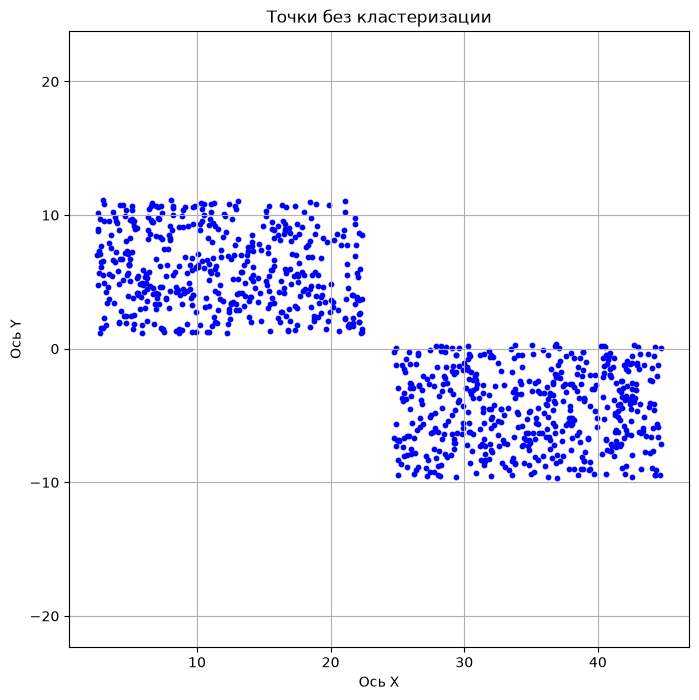

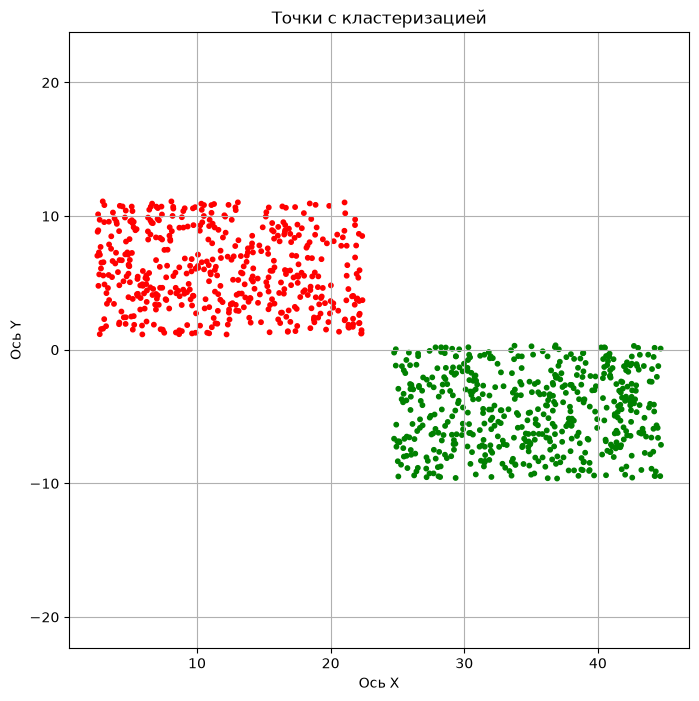

Лучшая точка 'green': (34.9263513155908, -4.6952764918914)
Лучшая точка 'red': (11.33408020339, 5.96596108062826)
Усреднение: 23130.215759490402, 635.3422943684297


In [106]:
plot_table(t2)
x2, y2 = get_cords(t2)
color2 = np.where(y2 > 0.5, 'red', 'green')
plot_table(t2, color2, True)
find(t2, color2)

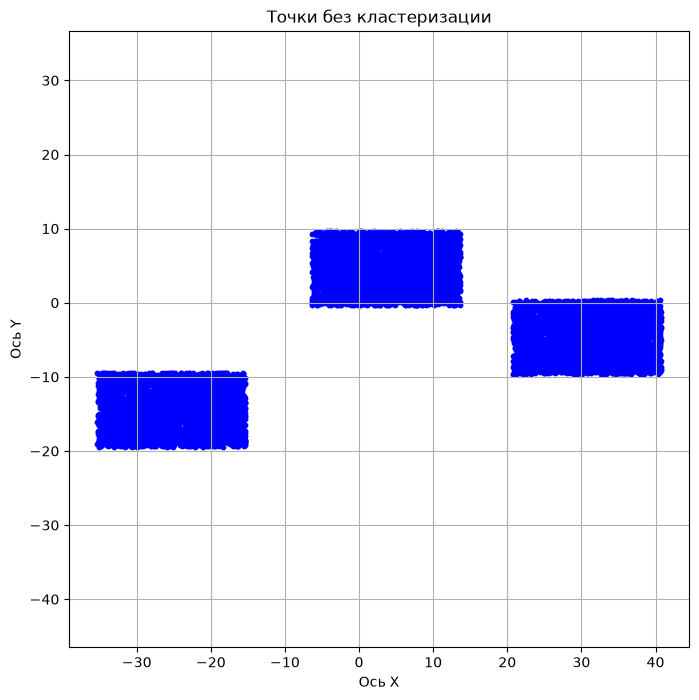

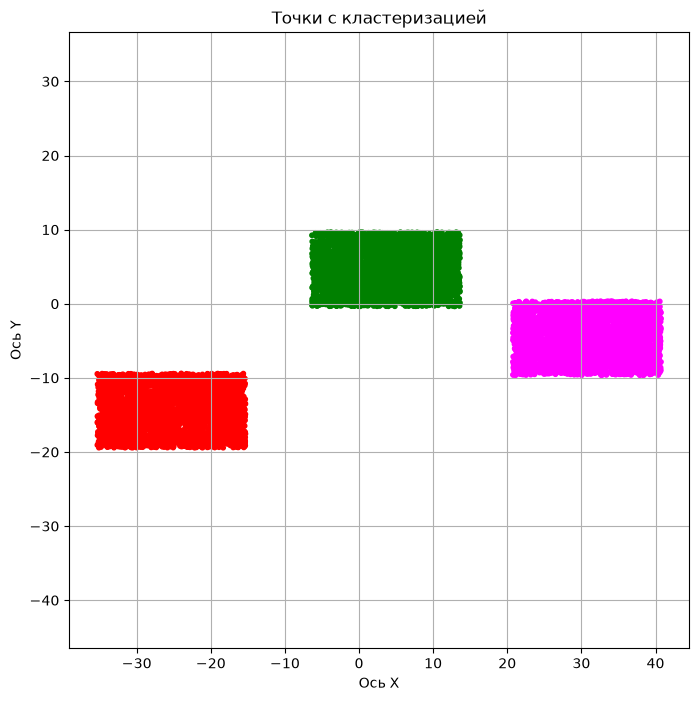

Лучшая точка 'green': (3.51791128381387, 4.65369555801186)
Лучшая точка 'magenta': (30.8495291640572, -4.51720290933603)
Лучшая точка 'red': (-25.1307584045602, -14.4133283639855)
Усреднение: 3078.8940144369562, -4758.945238436557


In [117]:
plot_table(t3)
x3, y3 = get_cords(t3)
cond3 = [x3 < -10,
        (x3 >= -10) & (x3 < 20),
        20 <= x3]
color3 = np.select(cond3, colors_list, default = 'black')
plot_table(t3, color3, True)
find(t3, color3, metric = 'manhattan')

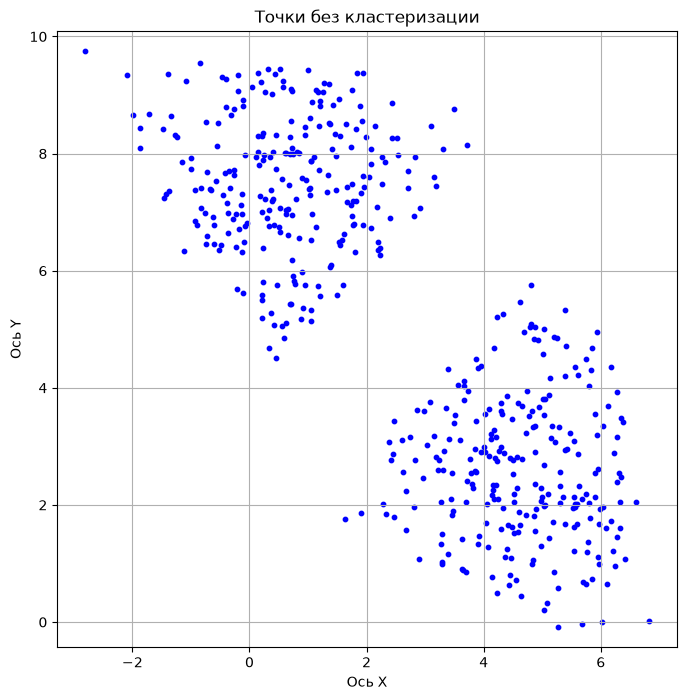

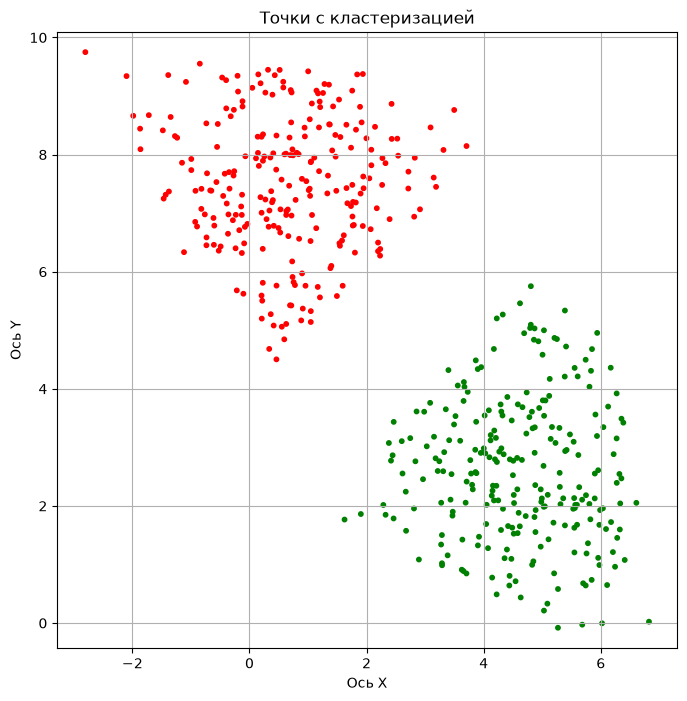

Лучшая точка 'green': (4.4992892332316, 2.5248135549032)
Лучшая точка 'red': (0.67779061055821, 7.4683214519915)
Усреднение: 2588.539921894905, 4996.567503447351


In [118]:
plot_table(t4)
x4, y4 = get_cords(t4)
color4 = np.where(y4 > x4 + 2, 'red', 'green')
plot_table(t4, color4, True)
find(t4, color4, metric = 'manhattan')

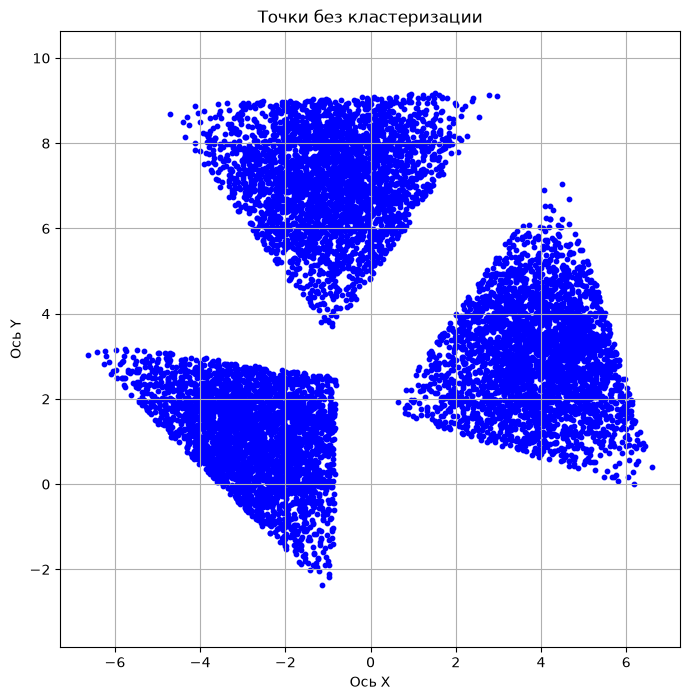

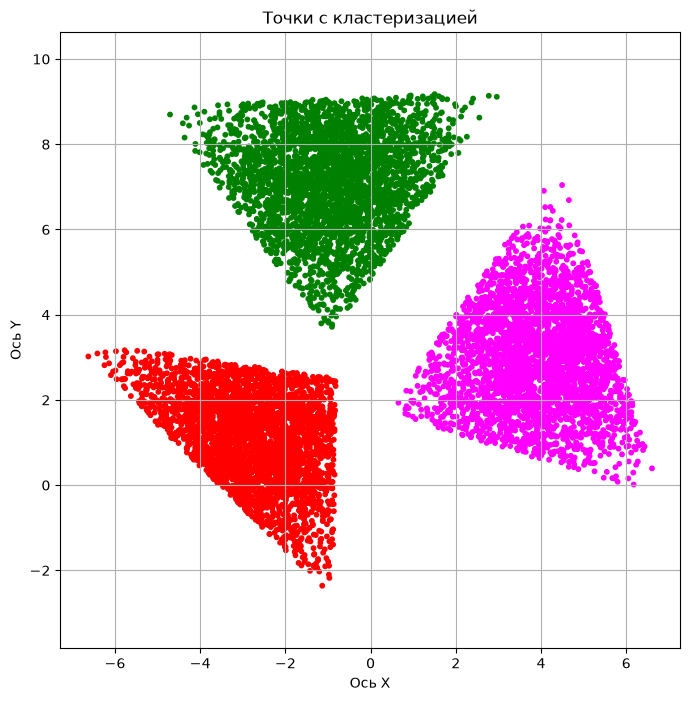

Лучшая точка 'green': (-0.92395441683756, 7.1198601472395)
Лучшая точка 'magenta': (3.8585848100911, 2.9071669740048)
Лучшая точка 'red': (-2.7496738270139, 1.1430593180752)
Усреднение: 61.65218874654673, 3723.362146439834


In [126]:
plot_table(t5)
x5, y5 = get_cords(t5)
cond5 = [y5 < -x5 + 2,
        (y5 >= -x5) & (y5 > x5 + 4),
        (y5 >= -x5) & (y5 <= x5 + 4)]
color5 = np.select(cond5, colors_list, default = 'black')
plot_table(t5, color5, True)
find(t5, color5)